# Train the circuit board defect detector (RF-DETR) on Colab

Fine-tunes **RF-DETR Nano** to find four defects on circuit boards (bent pins, melted
solder, scratches, missing components), on the **VisA** dataset (PCB1-3). The weights it
produces run on a CPU in `cv-conveyor`, the simulated conveyor that sends its results to
Odoo's Vision Inspection.

**Before running:** *Runtime → Change runtime type → T4 GPU*. Then *Runtime → Run all*.
About an hour on a T4: downloading VisA (1.9 GB) takes a few minutes, training most of it.

Licences: VisA © Amazon, [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/);
RF-DETR Nano, Apache-2.0; this project, Apache-2.0.

## 1. GPU

In [1]:
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-cae3acba-817b-9c72-be2c-e2e3579e07ec)


## 2. The project

The same commands as on a laptop: `cv-prepare`, `cv-train`, `cv-evaluate`.

In [2]:
!git clone -q https://github.com/EricRForgeFlow/cv_quality_edge_demo.git
%cd cv_quality_edge_demo
!pip install -q -e ".[train]"

/content/cv_quality_edge_demo
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for cv-quality-edge-demo (pyproject.toml) ... done


## 3. The dataset

Downloads VisA, keeps PCB1-3 and turns their defect masks into boxes (COCO format).

In [3]:
!cv-prepare

{
  "train": {
    "defective": 210,
    "bent": 50,
    "melt": 214,
    "scratch": 67,
    "missing": 77,
    "good": 210
  },
  "valid": {
    "defective": 45,
    "bent": 11,
    "melt": 47,
    "missing": 14,
    "scratch": 15,
    "good": 45
  },
  "test": {
    "defective": 45,
    "bent": 9,
    "melt": 45,
    "missing": 25,
    "scratch": 18,
    "good": 45
  }
}
COCO dataset in dataset/ (0 masks without defects skipped)


## 4. Training

`nano` is the model the conveyor runs on a CPU. If its scores below are poor, set
`MODEL = "small"` (also Apache-2.0) and run this cell and the next ones again.

In [4]:
MODEL = "nano"
!cv-train --preset colab --model {MODEL}

[2026-10-28 11:36:03] [INFO] rf-detr - Downloading pretrained weights for /root/.roboflow/models/rf-detr-nano.pth
/root/.roboflow/models/rf-detr-nano.pth: 100% 349M/349M [00:05<00:00, 67.7MiB/s]
[2026-10-28 11:36:09] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-nano.pth
[2026-10-28 11:36:09] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-28 11:36:09] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-28 11:36:11] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-nano.pth already exists with correct MD5 hash.
[2026-10-28 11:36:19] [WARNING] rf-detr - [auto-batch] 1/465 trainable params received no gradient from the synthetic probe batch; their optimizer state is

## 5. Scores on the test boards (never seen in training)

`map50`: how well it finds each defect where it is. `boards`: what quality control cares
about: defective boards caught (`recall`) and how often a rejected board really was
defective (`precision`).

In [5]:
!cv-evaluate --model models/pcb_{MODEL}.pth

/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-10-28 12:04:35] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-28 12:04:35] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is

## 6. A look at a few test boards

/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
/usr/local/lib/python3.13/dist-packages/rfdetr/detr.py:841: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-10-28 12:04:51] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-28 12:04:51] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is

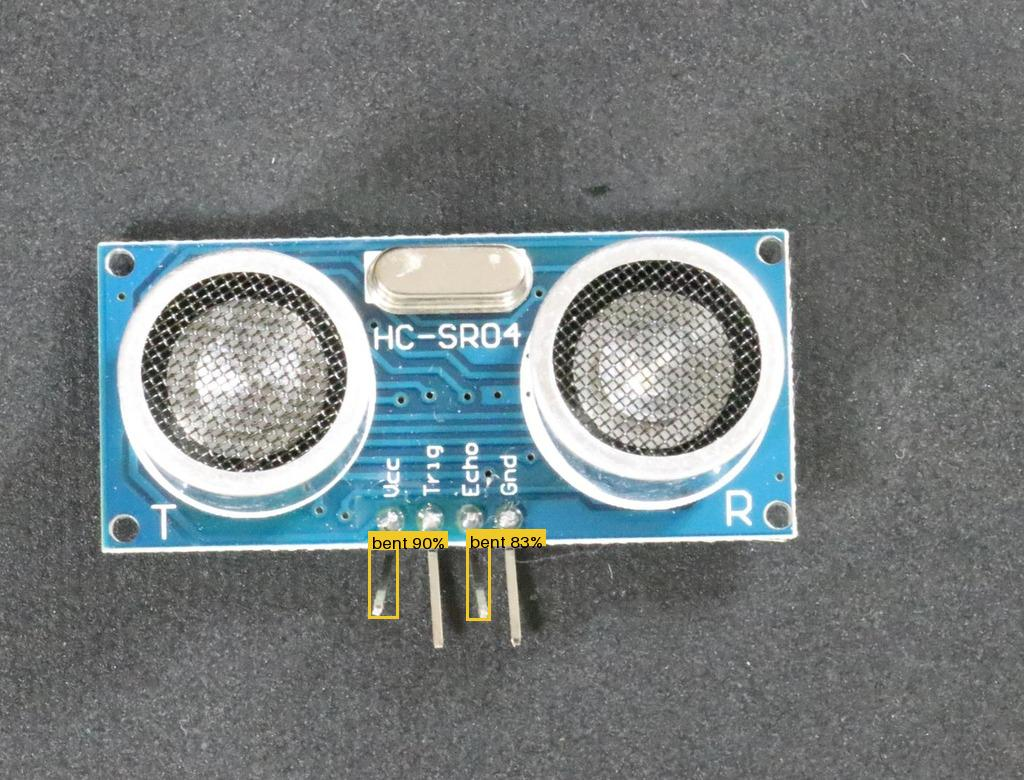

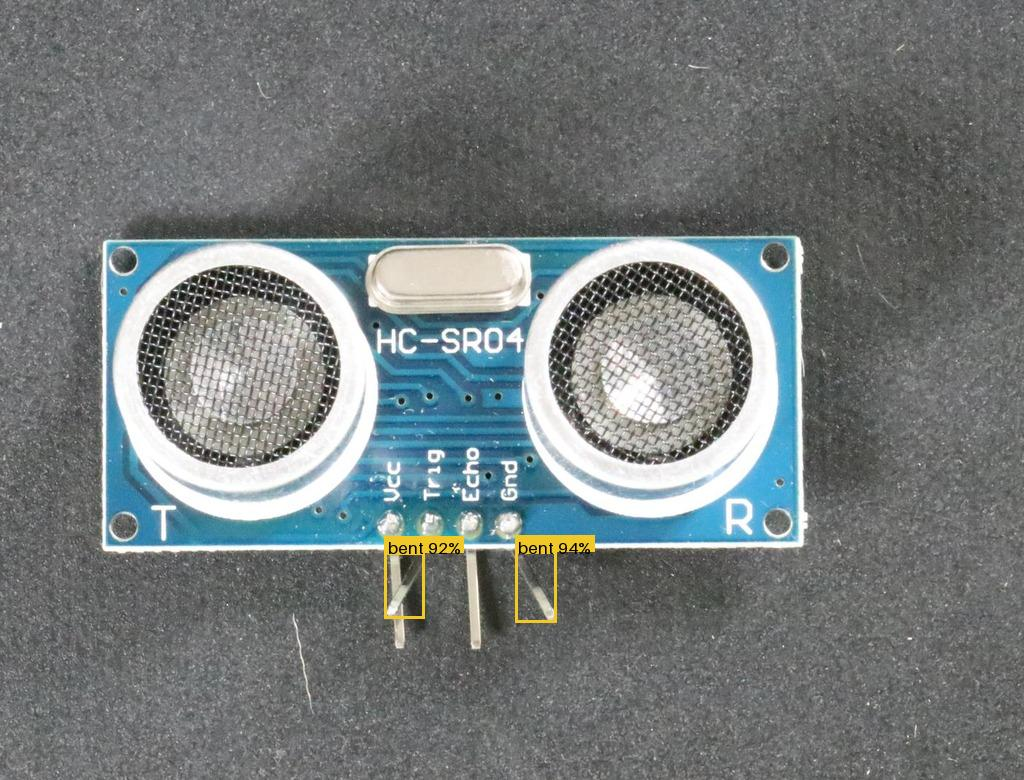

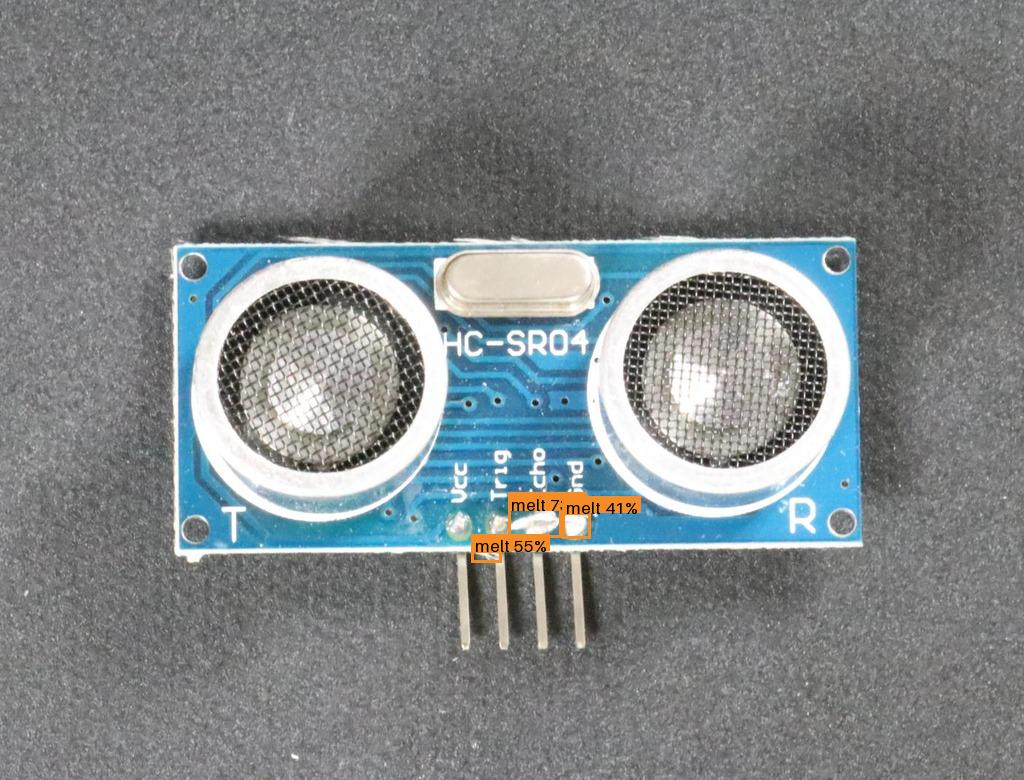

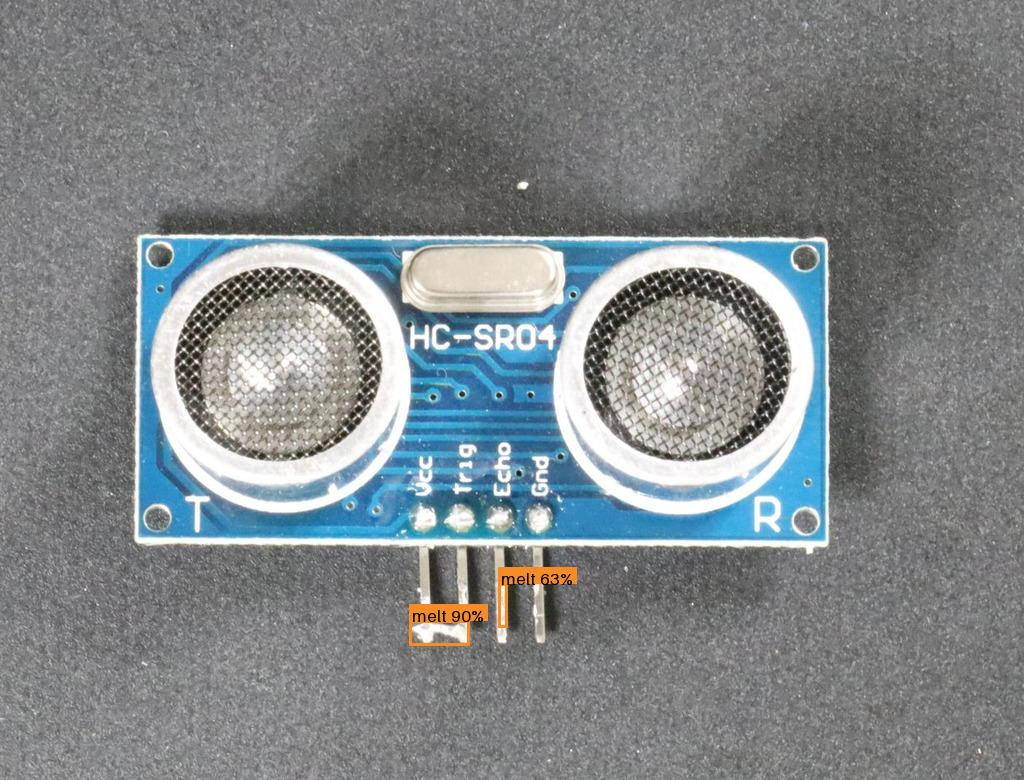

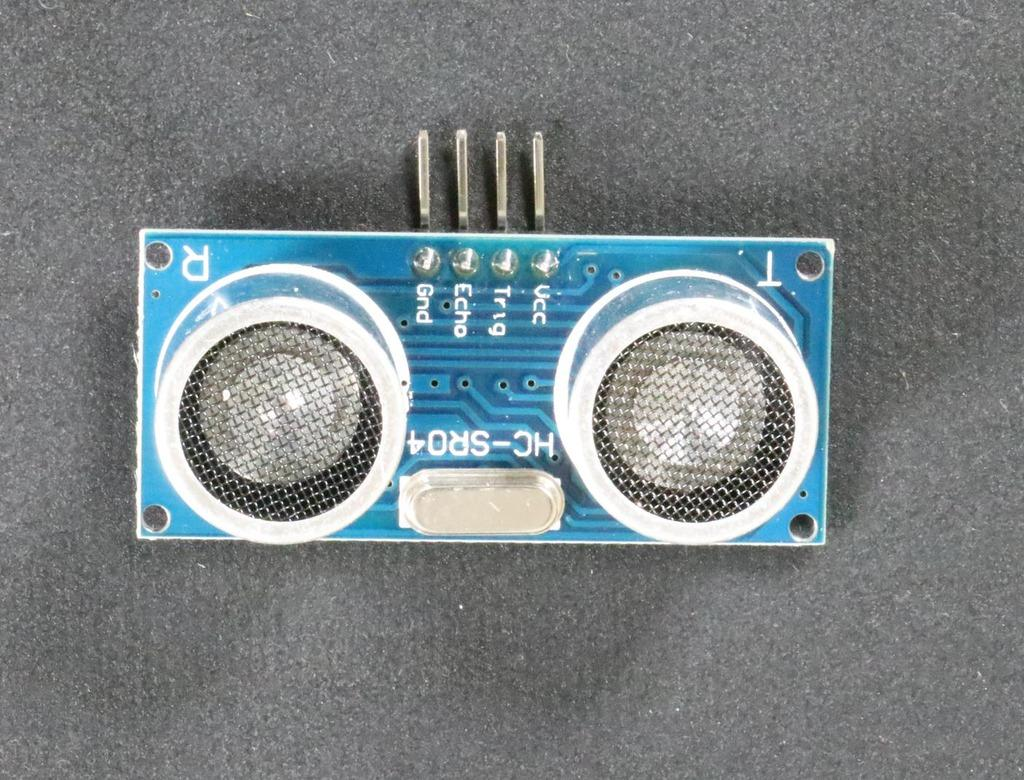

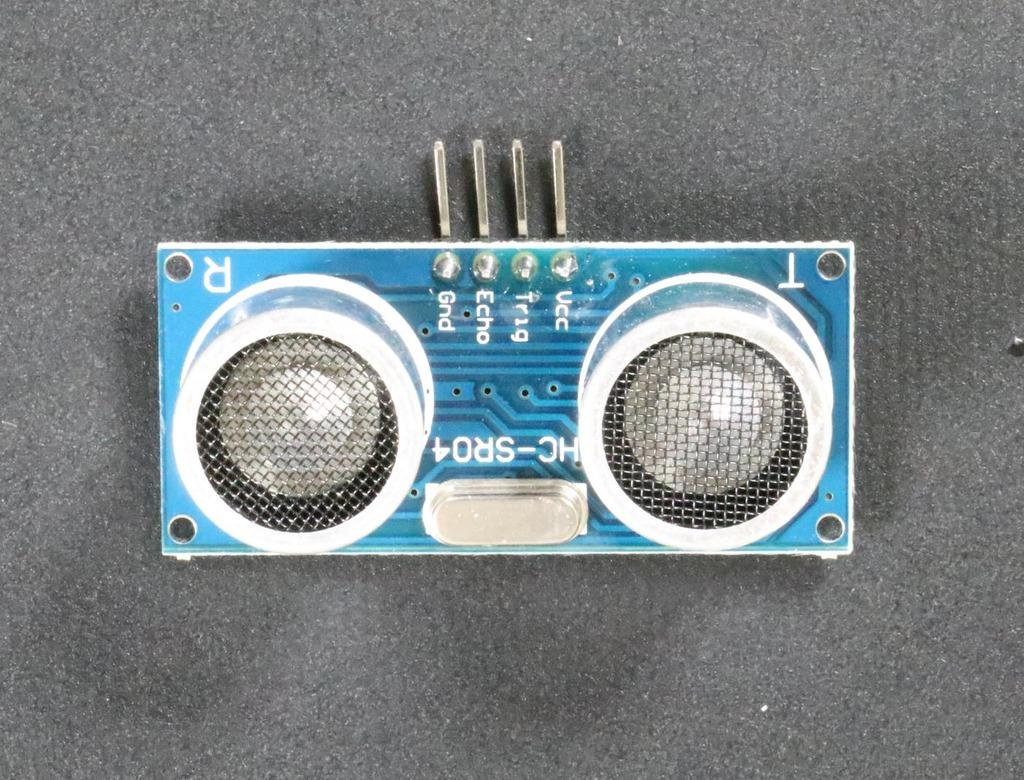

In [6]:
import glob, json
from IPython.display import Image, display

with open("dataset/test/_annotations.coco.json") as handle:
    coco = json.load(handle)
defective = {a["image_id"] for a in coco["annotations"]}
samples = [i["file_name"] for i in coco["images"] if i["id"] in defective][:4]
samples += [i["file_name"] for i in coco["images"] if i["id"] not in defective][:2]
paths = " ".join(f"dataset/test/{name}" for name in samples)
!cv-detect {paths} --model models/pcb_{MODEL}.pth
for name in samples:
    display(Image(f"runs/detect/{name}", width=640))

## 7. Keep the weights

Copies the weights and their scores to Google Drive (`MyDrive/cv_quality_edge_demo/`) and
downloads them. On your machine, put the `.pth` in the project's `models/` folder.

In [7]:
import os, shutil
from google.colab import drive, files

drive.mount("/content/drive")
target = "/content/drive/MyDrive/cv_quality_edge_demo"
os.makedirs(target, exist_ok=True)
for path in (f"models/pcb_{MODEL}.pth", f"models/pcb_{MODEL}.metrics.json"):
    shutil.copy(path, target)
    files.download(path)
print("Saved to", target)

Mounted at /content/drive


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved to /content/drive/MyDrive/cv_quality_edge_demo
